In [4]:
!nvidia-smi

Wed Nov 25 09:58:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!pip install numba -q
import numpy as np
from numba import cuda
import time
n = 10_000_000
a = np.random.rand(n).astype(np.float32)
b = np.random.rand(n).astype(np.float32)

start = time.time()
c_cpu = a + b
end = time.time()

print("CPU time:", end - start, "seconds")

CPU time: 0.01605510711669922 seconds


In [4]:
from numba import cuda

a_gpu = cuda.to_device(a)
b_gpu = cuda.to_device(b)
c_gpu = cuda.device_array_like(a_gpu)

@cuda.jit
def add_kernel(a, b, c):
    i = cuda.grid(1)
    if i < a.size:
        c[i] = a[i] + b[i]

threads_per_block = 256
blocks_per_grid = (n + threads_per_block - 1) // threads_per_block


add_kernel[blocks_per_grid, threads_per_block](a_gpu, b_gpu, c_gpu)
cuda.synchronize()

start = time.time()
add_kernel[blocks_per_grid, threads_per_block](a_gpu, b_gpu, c_gpu)
cuda.synchronize()
end = time.time()

print("GPU time:", end - start, "seconds")

GPU time: 0.0007193088531494141 seconds


Image shape: (668, 500, 3)


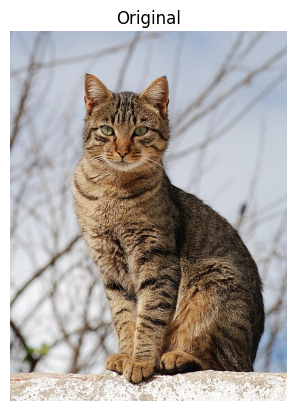

In [5]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open("images.jpg").convert("RGB")
img_array = np.array(img).astype(np.float32) / 255.0

print("Image shape:", img_array.shape)
plt.imshow(img)
plt.title("Original")
plt.axis("off")
plt.show()

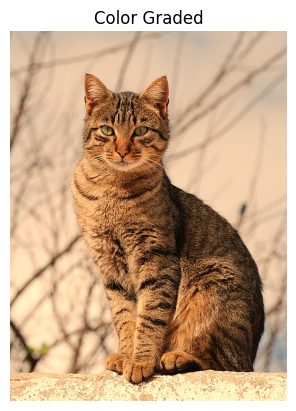

In [6]:
color_matrix = np.array([
    [1.2, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.0, 0.0, 0.8]
], dtype=np.float32)

graded = img_array @ color_matrix.T
graded = np.clip(graded, 0, 1)

plt.imshow(graded)
plt.title("Color Graded")
plt.axis("off")
plt.show()

In [7]:
from numba import cuda
import numpy as np
import time

@cuda.jit
def grade_kernel(img, matrix, out):
    x, y = cuda.grid(2)
    if x < img.shape[0] and y < img.shape[1]:
        r = img[x, y, 0]
        g = img[x, y, 1]
        b = img[x, y, 2]
        out[x, y, 0] = r * matrix[0, 0] + g * matrix[0, 1] + b * matrix[0, 2]
        out[x, y, 1] = r * matrix[1, 0] + g * matrix[1, 1] + b * matrix[1, 2]
        out[x, y, 2] = r * matrix[2, 0] + g * matrix[2, 1] + b * matrix[2, 2]

CPU time: 5.663 ms
GPU time: 0.325 ms
Speedup: 17.44x


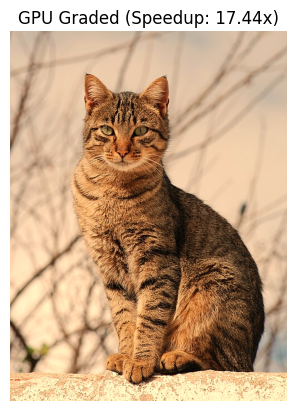

In [8]:
#prepare data on the GPU
img_gpu = cuda.to_device(img_array)
matrix_gpu = cuda.to_device(color_matrix)
out_gpu = cuda.device_array_like(img_gpu)

height, width, _ = img_array.shape
threads_per_block = (16, 16)
blocks_per_grid_x = (height + threads_per_block[0] - 1) // threads_per_block[0]
blocks_per_grid_y = (width + threads_per_block[1] - 1) // threads_per_block[1]
blocks_per_grid = (blocks_per_grid_x, blocks_per_grid_y)

#compilation happens here
grade_kernel[blocks_per_grid, threads_per_block](img_gpu, matrix_gpu, out_gpu)
cuda.synchronize()

#real timed GPU run
start = time.time()
grade_kernel[blocks_per_grid, threads_per_block](img_gpu, matrix_gpu, out_gpu)
cuda.synchronize()
gpu_time = time.time() - start

#real timed CPU run
start = time.time()
graded_cpu = img_array @ color_matrix.T
graded_cpu = np.clip(graded_cpu, 0, 1)
cpu_time = time.time() - start

print(f"CPU time: {cpu_time*1000:.3f} ms")
print(f"GPU time: {gpu_time*1000:.3f} ms")
print(f"Speedup: {cpu_time/gpu_time:.2f}x")


result = out_gpu.copy_to_host()
result = np.clip(result, 0, 1)
plt.imshow(result)
plt.title(f"GPU Graded (Speedup: {cpu_time/gpu_time:.2f}x)")
plt.axis("off")
plt.show()

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 164MB/s]


Found 1 cat(s)


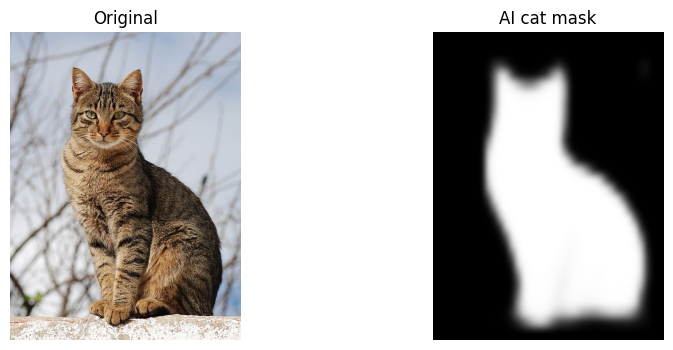

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import time
from PIL import Image
from numba import cuda

img = Image.open("images.jpg").convert("RGB")
img_array = np.array(img).astype(np.float32) / 255.0
height, width, _ = img_array.shape

#GPU launch configuration
img_gpu = cuda.to_device(img_array)
threads_per_block = (16, 16)
blocks_per_grid = (
    (height + threads_per_block[0] - 1) // threads_per_block[0],
    (width + threads_per_block[1] - 1) // threads_per_block[1],
)


color_matrix = np.array([[1.2, 0.0, 0.0],
                         [0.0, 1.0, 0.0],
                         [0.0, 0.0, 0.8]], dtype=np.float32)
result = np.clip(img_array @ color_matrix.T, 0, 1)

import torch, torch.nn.functional as F
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import gaussian_blur

device = "cuda" if torch.cuda.is_available() else "cpu"
model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT).to(device).eval()
CAT_ID = 17

# Default-size handling
MAX_SIDE = 800
scale = min(1.0, MAX_SIDE / max(height, width))
small_h, small_w = int(height * scale), int(width * scale)

tensor = torch.from_numpy(img_array).permute(2, 0, 1).unsqueeze(0).to(device)
small = F.interpolate(tensor, size=(small_h, small_w), mode="bilinear", align_corners=False)

with torch.no_grad():
    pred = model([small[0]])[0]

cat_masks = [pred["masks"][i, 0] for i in range(len(pred["labels"]))
             if pred["labels"][i].item() == CAT_ID and pred["scores"][i].item() > 0.7]

if cat_masks:
    mask_small = torch.stack(cat_masks).max(dim=0).values
    print(f"Found {len(cat_masks)} cat(s)")
else:
    mask_small = torch.zeros(small_h, small_w, device=device)
    print("No cat found, edits will apply to the whole image as background")


mask_full = F.interpolate(mask_small[None, None], size=(height, width), mode="bilinear", align_corners=False)
mask_full = gaussian_blur(mask_full, kernel_size=31)[0, 0]
mask_np = mask_full.clamp(0, 1).cpu().numpy().astype(np.float32)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img);                      plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(mask_np, cmap="gray");     plt.title("AI cat mask"); plt.axis("off")
plt.show()

In [10]:
lum_map = 0.2126 * img_array[..., 0] + 0.7152 * img_array[..., 1] + 0.0722 * img_array[..., 2]

def region_mean(weight):
    return float((lum_map * weight).sum() / (weight.sum() + 1e-6))

cat_lum = region_mean(mask_np) if mask_np.sum() > 1 else region_mean(np.ones_like(mask_np))
bg_lum  = region_mean(1 - mask_np)
print(f"Cat brightness: {cat_lum:.3f} | Background brightness: {bg_lum:.3f}")


cat_ev = float(np.clip(np.log2(0.45 / max(cat_lum, 1e-3)), -1.5, 1.5))
bg_ev  = float(np.clip(np.log2(0.40 / max(bg_lum,  1e-3)), -1.0, 1.0)) - 0.15

subject_params    = np.array([cat_ev, 0.15, -0.20, 0.25, 0.20,  0.05], dtype=np.float32)
background_params = np.array([bg_ev,  0.05, -0.10, 0.10, -0.15, -0.03], dtype=np.float32)
print("Subject params:", subject_params)
print("Background params:", background_params)

Cat brightness: 0.386 | Background brightness: 0.741
Subject params: [ 0.22315393  0.15       -0.2         0.25        0.2         0.05      ]
Background params: [-1.0400109  0.05      -0.1        0.1       -0.15      -0.03     ]


In [11]:
#Lightroom-style GPU edit
import math

@cuda.jit(device=True)
def edit_pixel(r, g, b, p):
    # Exposure
    gain = 2.0 ** p[0]
    r *= gain; g *= gain; b *= gain

    # White balance / temperature
    r *= 1.0 + p[5]; b *= 1.0 - p[5]

    # Highlights & shadows weighted by brightness
    lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
    lum = min(max(lum, 0.0), 1.0)
    lift = p[3] * (1.0 - lum) ** 2 * 0.5 + p[2] * lum ** 2 * 0.5
    r += lift; g += lift; b += lift

    # Contrast around mid-grey
    k = 1.0 + p[1]
    r = (r - 0.5) * k + 0.5
    g = (g - 0.5) * k + 0.5
    b = (b - 0.5) * k + 0.5

    # Saturation
    l2 = 0.2126 * r + 0.7152 * g + 0.0722 * b
    s = 1.0 + p[4]
    r = l2 + (r - l2) * s
    g = l2 + (g - l2) * s
    b = l2 + (b - l2) * s
    return min(max(r, 0.0), 1.0), min(max(g, 0.0), 1.0), min(max(b, 0.0), 1.0)

@cuda.jit
def lightroom_kernel(img, mask, p_subject, p_bg, vignette, out):
    i, j = cuda.grid(2)
    h, w = img.shape[0], img.shape[1]
    if i < h and j < w:
        r, g, b = img[i, j, 0], img[i, j, 1], img[i, j, 2]
        sr, sg, sb = edit_pixel(r, g, b, p_subject)
        br, bg_, bb = edit_pixel(r, g, b, p_bg)
        m = mask[i, j]
        r = sr * m + br * (1.0 - m)
        g = sg * m + bg_ * (1.0 - m)
        b = sb * m + bb * (1.0 - m)

        # Vignette: darken edges
        dy = (i - h / 2.0) / (h / 2.0)
        dx = (j - w / 2.0) / (w / 2.0)
        v = 1.0 - vignette * (dx * dx + dy * dy) * 0.5
        out[i, j, 0] = r * v
        out[i, j, 1] = g * v
        out[i, j, 2] = b * v

@cuda.jit
def sharpen_kernel(src, mask, amount_subject, amount_bg, out):
    # Unsharp mask using a 3x3 box blur; cat gets more sharpening than background
    i, j = cuda.grid(2)
    h, w = src.shape[0], src.shape[1]
    if i < h and j < w:
        amt = amount_subject * mask[i, j] + amount_bg * (1.0 - mask[i, j])
        for c in range(3):
            total = 0.0
            for di in range(-1, 2):
                for dj in range(-1, 2):
                    ii = min(max(i + di, 0), h - 1)
                    jj = min(max(j + dj, 0), w - 1)
                    total += src[ii, jj, c]
            blur = total / 9.0
            val = src[i, j, c] + amt * (src[i, j, c] - blur)
            out[i, j, c] = min(max(val, 0.0), 1.0)

# Upload and run
mask_gpu = cuda.to_device(mask_np)
ps_gpu   = cuda.to_device(subject_params)
pb_gpu   = cuda.to_device(background_params)
edited_gpu  = cuda.device_array_like(img_gpu)
sharpen_gpu = cuda.device_array_like(img_gpu)

def run_pipeline():
    lightroom_kernel[blocks_per_grid, threads_per_block](img_gpu, mask_gpu, ps_gpu, pb_gpu, np.float32(0.35), edited_gpu)
    sharpen_kernel[blocks_per_grid, threads_per_block](edited_gpu, mask_gpu, np.float32(0.8), np.float32(0.2), sharpen_gpu)

run_pipeline(); cuda.synchronize()          #compile

start = time.time()
run_pipeline(); cuda.synchronize()
pipeline_gpu_time = time.time() - start
print(f"Full AI-edit pipeline on GPU: {pipeline_gpu_time*1000:.3f} ms")

Full AI-edit pipeline on GPU: 3.859 ms


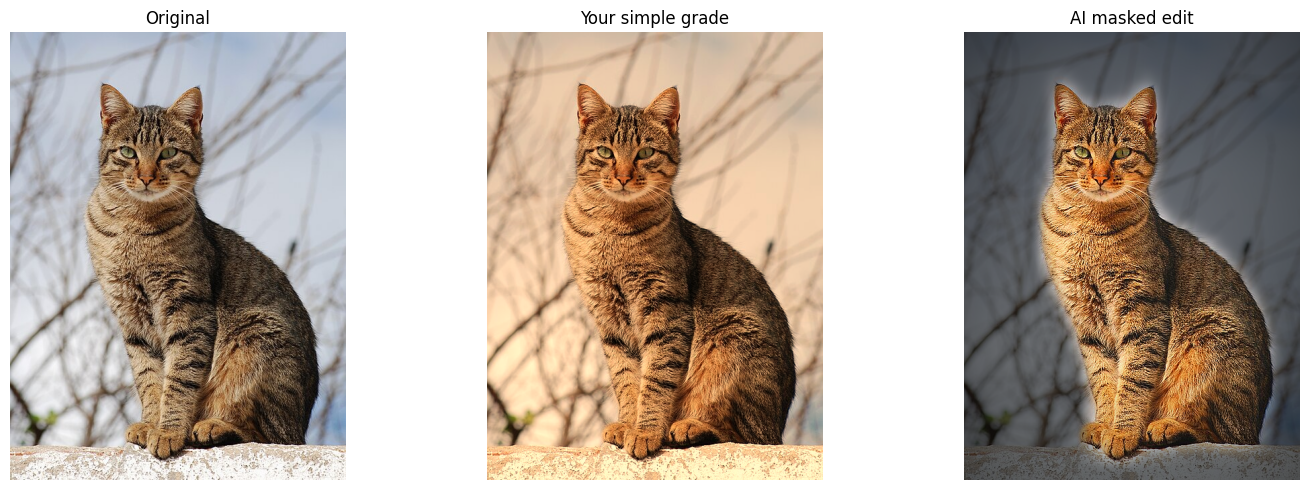

In [12]:
#Comparision
final = sharpen_gpu.copy_to_host()

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(img_array);   plt.title("Original");           plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(result);      plt.title("Your simple grade");  plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(final);       plt.title("AI masked edit");     plt.axis("off")
plt.tight_layout(); plt.show()

PyTorch GPU: Tesla T4
Numba CUDA available: True

Original image information
--------------------------
Image dimensions: 500 x 668
Original megapixels: 0.334
Device: cuda

Loading Mask R-CNN...

Mask R-CNN performance
----------------------
CPU inference: 6800.49 ms
GPU inference: 126.55 ms
GPU speedup: 53.74x
Cats detected: 1

Image brightness analysis
-------------------------
Subject brightness: 0.3855
Background brightness: 0.7413
Subject parameters: [ 0.22315393  0.15       -0.2         0.25        0.2         0.05      ]
Background parameters: [-1.0400107  0.05      -0.1        0.1       -0.15      -0.03     ]

Starting resolution experiments...

--- 0.25 MP (432 x 577) ---
RAW: CPU 2.56 ms | GPU 2.40 ms | 1.07x
EDITED: CPU 45.04 ms | GPU 10.68 ms | 4.22x
GPU kernels only: 2.71 ms
PSNR: 141.94 dB | SSIM: 1.00000
Raw maximum absolute error: 0.00000000

--- 1 MP (865 x 1155) ---
RAW: CPU 11.76 ms | GPU 6.82 ms | 1.72x
EDITED: CPU 214.76 ms | GPU 33.10 ms | 6.49x
GPU kernels only: 

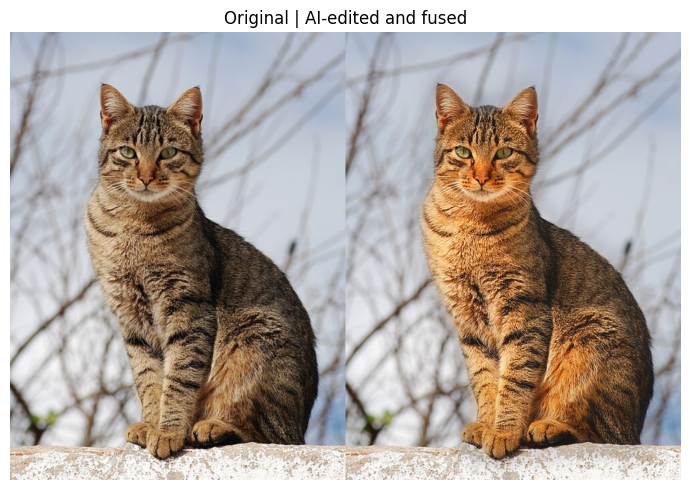

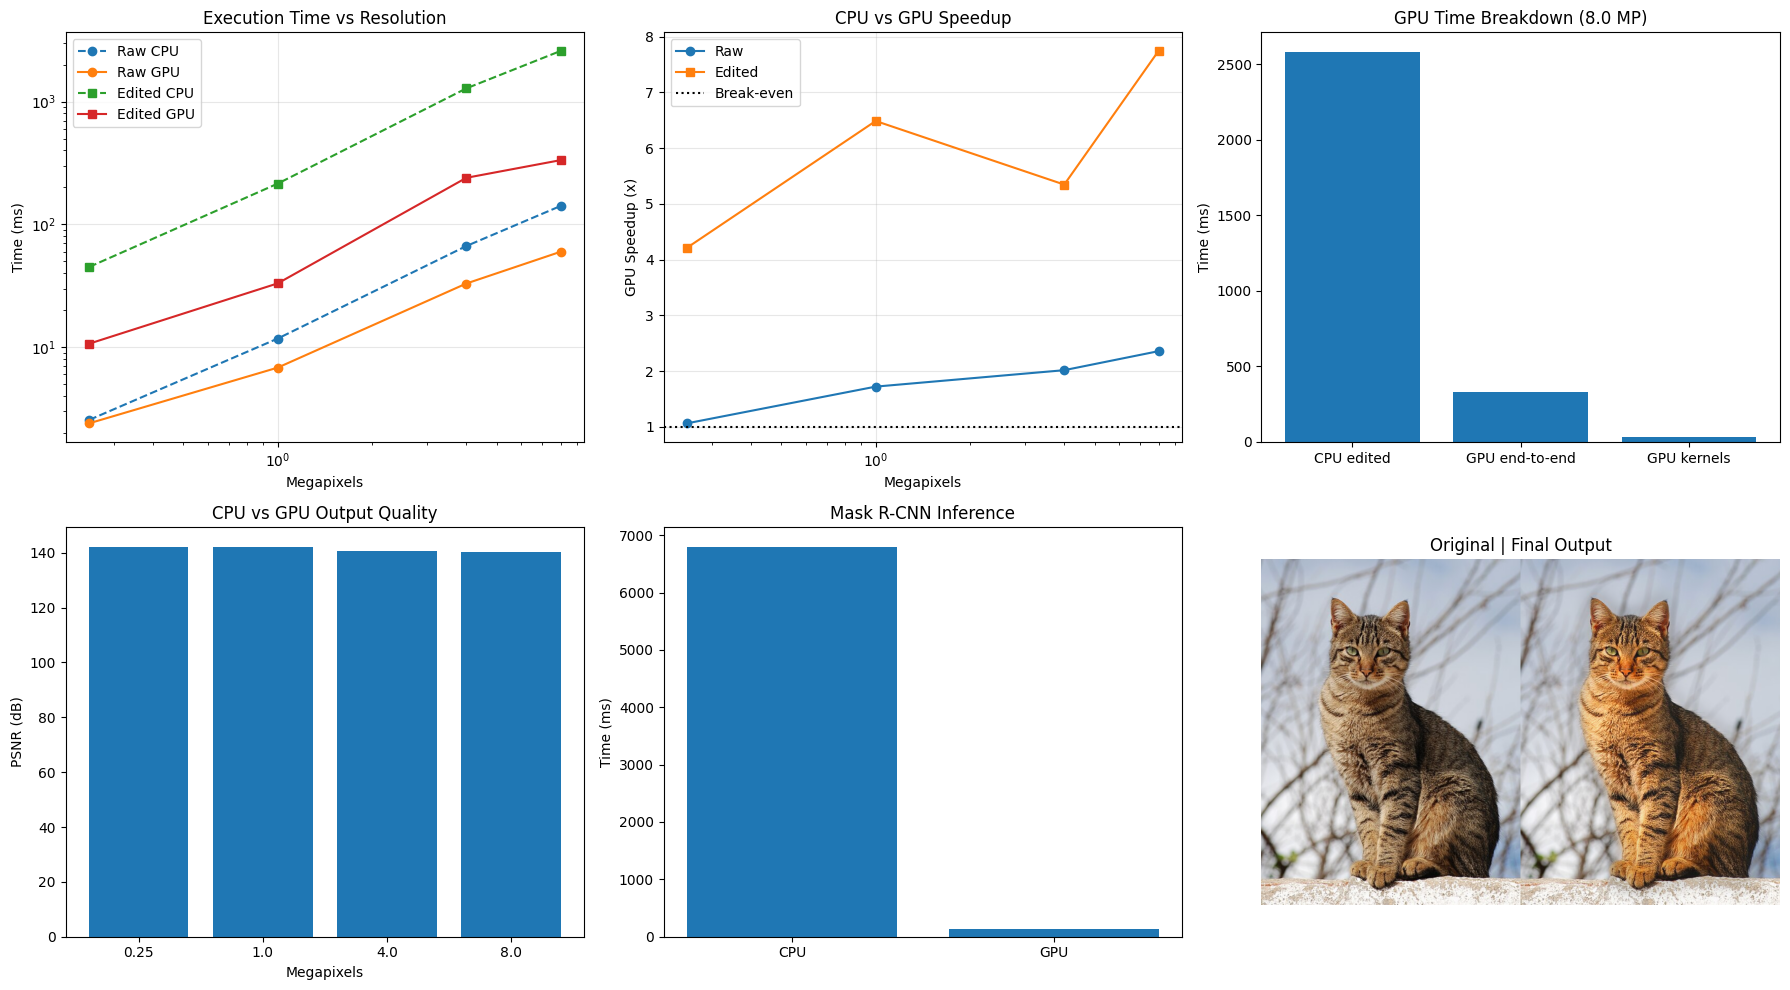


EXPERIMENT COMPLETED
Saved:
- results.csv
- detection_results.csv
- dashboard.png
- before_after.png


In [13]:
#extra
# ============================================================
# CPU vs GPU IMAGE EDITING RESEARCH
# ALL-IN-ONE EXPERIMENT
# ============================================================

import cv2
import math
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from PIL import Image
from numba import cuda
from scipy.ndimage import uniform_filter

from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)
from torchvision.transforms.functional import gaussian_blur

from skimage.metrics import (
    peak_signal_noise_ratio as psnr_fn,
    structural_similarity as ssim_fn
)

# ============================================================
# 0. CONFIGURATION
# ============================================================

IMAGE_FILE = "images.jpg"

# Test different image resolutions
MEGAPIXELS = [0.25, 1, 4, 8]

# GPU threads
TPB = (16, 16)

# Device verification
torch_gpu = torch.cuda.is_available()
numba_gpu = cuda.is_available()

if not torch_gpu or not numba_gpu:
    raise RuntimeError(
        "A CUDA-compatible GPU is required. "
        "Enable GPU acceleration in your Colab runtime."
    )

device = "cuda"

print("PyTorch GPU:", torch.cuda.get_device_name(0))
print("Numba CUDA available:", numba_gpu)


def sync():
    """Wait for both GPU libraries to finish their work."""
    cuda.synchronize()
    torch.cuda.synchronize()


def bench(fn, repeats=5, warmup=True):
    """
    Benchmark a function.

    Warm-up runs are excluded.
    GPU execution is synchronised.
    Median time is returned in milliseconds.
    """

    if warmup:
        fn()
        sync()

    times = []
    output = None

    for _ in range(repeats):
        start = time.perf_counter()

        output = fn()
        sync()

        end = time.perf_counter()
        times.append(end - start)

    return float(np.median(times)) * 1000, output


def grid_for(h, w):
    """Calculate the number of GPU blocks."""
    return (
        (h + TPB[0] - 1) // TPB[0],
        (w + TPB[1] - 1) // TPB[1]
    )


# ============================================================
# 1. LOAD IMAGE
# ============================================================

img_array = (
    np.array(
        Image.open(IMAGE_FILE).convert("RGB")
    ).astype(np.float32) / 255.0
)

H0, W0 = img_array.shape[:2]

print("\nOriginal image information")
print("--------------------------")
print("Image dimensions:", W0, "x", H0)
print("Original megapixels:", round(H0 * W0 / 1e6, 4))
print("Device:", device)

# Colour transformation matrix
color_matrix = np.array([
    [1.2, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.0, 0.0, 0.8]
], dtype=np.float32)


# ============================================================
# 2. AI SUBJECT DETECTION USING MASK R-CNN
# ============================================================

print("\nLoading Mask R-CNN...")

model = maskrcnn_resnet50_fpn(
    weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT
).eval()

# Resize the input for AI detection
scale = min(1.0, 800 / max(H0, W0))

sh = int(H0 * scale)
sw = int(W0 * scale)

tensor = torch.from_numpy(img_array).permute(2, 0, 1).unsqueeze(0)

small = F.interpolate(
    tensor,
    size=(sh, sw),
    mode="bilinear",
    align_corners=False
)


def detect(dev):
    """Measure Mask R-CNN inference on a selected device."""

    model.to(dev)
    x = small[0].to(dev)

    with torch.no_grad():

        # Warm-up inference
        model([x])

        if dev == "cuda":
            torch.cuda.synchronize()

        # Actual timed inference
        start = time.perf_counter()

        pred = model([x])[0]

        if dev == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

    return (end - start) * 1000, pred


# GPU inference
gpu_detect_ms, pred_gpu = detect("cuda")

# CPU inference
cpu_detect_ms, pred_cpu = detect("cpu")

print("\nMask R-CNN performance")
print("----------------------")
print(f"CPU inference: {cpu_detect_ms:.2f} ms")
print(f"GPU inference: {gpu_detect_ms:.2f} ms")
print(f"GPU speedup: {cpu_detect_ms / gpu_detect_ms:.2f}x")

# Use GPU prediction for subsequent processing
pred = {k: v.cpu() for k, v in pred_gpu.items()}

# COCO category ID for cat
CAT_ID = 17

# Confidence threshold
cats = [
    pred["masks"][i, 0]
    for i in range(len(pred["labels"]))
    if pred["labels"][i].item() == CAT_ID
    and pred["scores"][i].item() > 0.7
]

if cats:
    m_small = torch.stack(cats).max(dim=0).values
    print("Cats detected:", len(cats))
else:
    m_small = torch.zeros(sh, sw)
    print("No cat detected. Whole image treated as background.")

# Resize mask to original image dimensions
m_full = F.interpolate(
    m_small[None, None],
    size=(H0, W0),
    mode="bilinear",
    align_corners=False
)

# Smooth mask boundaries
m_full = gaussian_blur(m_full, kernel_size=31)[0, 0]

mask_np = np.ascontiguousarray(
    m_full.clamp(0, 1).numpy().astype(np.float32)
)

# Save detection timing
pd.DataFrame({
    "Device": ["CPU", "GPU"],
    "Inference_time_ms": [cpu_detect_ms, gpu_detect_ms],
    "Speedup": [1.0, cpu_detect_ms / gpu_detect_ms]
}).to_csv("detection_results.csv", index=False)

del model, pred_gpu, pred_cpu, pred
gc.collect()
torch.cuda.empty_cache()


# ============================================================
# 3. AUTOMATIC IMAGE ANALYSIS
# ============================================================

# Calculate perceived brightness
lum_map = (
    0.2126 * img_array[..., 0]
    + 0.7152 * img_array[..., 1]
    + 0.0722 * img_array[..., 2]
)


def region_mean(weight):
    return float(
        (lum_map * weight).sum()
        / (weight.sum() + 1e-6)
    )


cat_lum = (
    region_mean(mask_np)
    if mask_np.sum() > 1
    else region_mean(np.ones_like(mask_np))
)

bg_lum = region_mean(1 - mask_np)

print("\nImage brightness analysis")
print("-------------------------")
print(f"Subject brightness: {cat_lum:.4f}")
print(f"Background brightness: {bg_lum:.4f}")


# Exposure compensation
cat_ev = float(np.clip(
    np.log2(0.45 / max(cat_lum, 1e-3)),
    -1.5, 1.5
))

bg_ev = float(np.clip(
    np.log2(0.40 / max(bg_lum, 1e-3)),
    -1.0, 1.0
)) - 0.15


# Editing parameters:
# [Exposure, Contrast, Highlights, Shadows,
#  Saturation, Temperature]

subject_params = np.array([
    cat_ev, 0.15, -0.20, 0.25, 0.20, 0.05
], dtype=np.float32)

background_params = np.array([
    bg_ev, 0.05, -0.10, 0.10, -0.15, -0.03
], dtype=np.float32)

print("Subject parameters:", subject_params)
print("Background parameters:", background_params)


# ============================================================
# 4. GPU IMAGE EDITING KERNELS
# ============================================================

@cuda.jit(device=True)
def edit_pixel(r, g, b, p):

    # Exposure
    gain = 2.0 ** p[0]

    r *= gain
    g *= gain
    b *= gain

    # White balance / temperature
    r *= 1.0 + p[5]
    b *= 1.0 - p[5]

    # Highlights and shadows
    lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
    lum = min(max(lum, 0.0), 1.0)

    # CORRECTED: squared brightness weighting
    lift = (
        p[3] * (1.0 - lum) ** 2 * 0.5
        + p[2] * lum ** 2 * 0.5
    )

    r += lift
    g += lift
    b += lift

    # Contrast
    k = 1.0 + p[1]

    r = (r - 0.5) * k + 0.5
    g = (g - 0.5) * k + 0.5
    b = (b - 0.5) * k + 0.5

    # Saturation
    l2 = 0.2126 * r + 0.7152 * g + 0.0722 * b

    s = 1.0 + p[4]

    r = l2 + (r - l2) * s
    g = l2 + (g - l2) * s
    b = l2 + (b - l2) * s

    return (
        min(max(r, 0.0), 1.0),
        min(max(g, 0.0), 1.0),
        min(max(b, 0.0), 1.0)
    )


# Lightroom-style editing
@cuda.jit
def lightroom_kernel(img, mask, p_subject, p_bg, vignette, out):

    i, j = cuda.grid(2)

    h, w = img.shape[0], img.shape[1]

    if i < h and j < w:

        r = img[i, j, 0]
        g = img[i, j, 1]
        b = img[i, j, 2]

        # Edit subject
        sr, sg, sb = edit_pixel(
            r, g, b, p_subject
        )

        # Edit background
        br, bg_, bb = edit_pixel(
            r, g, b, p_bg
        )

        # Blend subject and background
        m = mask[i, j]

        r = sr * m + br * (1.0 - m)
        g = sg * m + bg_ * (1.0 - m)
        b = sb * m + bb * (1.0 - m)

        # Vignette
        dy = (i - h / 2.0) / (h / 2.0)
        dx = (j - w / 2.0) / (w / 2.0)

        v = 1.0 - vignette * (dx * dx + dy * dy) * 0.5

        out[i, j, 0] = r * v
        out[i, j, 1] = g * v
        out[i, j, 2] = b * v


# Sharpening kernel
@cuda.jit
def sharpen_kernel(src, mask, amt_s, amt_b, out):

    i, j = cuda.grid(2)

    h, w = src.shape[0], src.shape[1]

    if i < h and j < w:

        amt = (
            amt_s * mask[i, j]
            + amt_b * (1.0 - mask[i, j])
        )

        for c in range(3):

            total = 0.0

            # 3x3 neighbourhood
            for di in range(-1, 2):
                for dj in range(-1, 2):

                    ii = min(max(i + di, 0), h - 1)
                    jj = min(max(j + dj, 0), w - 1)

                    total += src[ii, jj, c]

            blur = total / 9.0

            val = (
                src[i, j, c]
                + amt * (src[i, j, c] - blur)
            )

            out[i, j, c] = min(max(val, 0.0), 1.0)


# Basic colour grading kernel
@cuda.jit
def raw_grade_kernel(img, m, out):

    i, j = cuda.grid(2)

    if i < img.shape[0] and j < img.shape[1]:

        r = img[i, j, 0]
        g = img[i, j, 1]
        b = img[i, j, 2]

        for c in range(3):

            value = (
                r * m[c, 0]
                + g * m[c, 1]
                + b * m[c, 2]
            )

            out[i, j, c] = min(max(value, 0.0), 1.0)


# Upload constant parameters once
ps_d = cuda.to_device(subject_params)
pb_d = cuda.to_device(background_params)
cm_d = cuda.to_device(color_matrix)


# ============================================================
# 5. CPU EQUIVALENT IMAGE EDITING
# ============================================================

def edit_cpu(img, p):

    r = img[..., 0].copy()
    g = img[..., 1].copy()
    b = img[..., 2].copy()

    # Exposure
    gain = 2.0 ** p[0]

    r *= gain
    g *= gain
    b *= gain

    # Temperature
    r *= 1.0 + p[5]
    b *= 1.0 - p[5]

    # Brightness
    lum = np.clip(
        0.2126 * r + 0.7152 * g + 0.0722 * b,
        0, 1
    )

    # CORRECTED: same squared calculation as GPU
    lift = (
        p[3] * (1 - lum) ** 2 * 0.5
        + p[2] * lum ** 2 * 0.5
    )

    r += lift
    g += lift
    b += lift

    # Contrast
    k = 1.0 + p[1]

    r = (r - 0.5) * k + 0.5
    g = (g - 0.5) * k + 0.5
    b = (b - 0.5) * k + 0.5

    # Saturation
    l2 = 0.2126 * r + 0.7152 * g + 0.0722 * b

    s = 1.0 + p[4]

    r = l2 + (r - l2) * s
    g = l2 + (g - l2) * s
    b = l2 + (b - l2) * s

    return np.clip(
        np.stack([r, g, b], axis=-1),
        0, 1
    ).astype(np.float32)


def sharpen_cpu(src, mask, a_s, a_b):

    # 3x3 box blur
    blur = uniform_filter(
        src,
        size=(3, 3, 1),
        mode="nearest"
    )

    amt = (
        a_s * mask[..., None]
        + a_b * (1 - mask[..., None])
    )

    result = src + amt * (src - blur)

    return np.clip(result, 0, 1).astype(np.float32)


# ============================================================
# 6. MULTI-SCALE PYRAMID FUSION
# ============================================================

def pyr_sizes(h, w, levels):

    sizes = [(h, w)]

    for _ in range(levels):

        h = max(1, h // 2)
        w = max(1, w // 2)

        sizes.append((h, w))

    return sizes


def pyramid_blend(a, b, mask, levels=5):

    h, w = a.shape[:2]
    sizes = pyr_sizes(h, w, levels)

    m3 = np.repeat(
        mask[..., None],
        3,
        axis=2
    ).astype(np.float32)

    # Gaussian pyramid
    def gp(x):

        p = [x.astype(np.float32)]

        for hh, ww in sizes[1:]:

            p.append(
                cv2.resize(
                    p[-1],
                    (ww, hh),
                    interpolation=cv2.INTER_LINEAR
                )
            )

        return p

    # Laplacian pyramid
    def lp(g):

        out = [g[-1]]

        for i in range(len(g) - 1, 0, -1):

            hh, ww = sizes[i - 1]

            out.append(
                g[i - 1]
                - cv2.resize(
                    g[i],
                    (ww, hh),
                    interpolation=cv2.INTER_LINEAR
                )
            )

        return out

    lA = lp(gp(a))
    lB = lp(gp(b))
    gM = gp(m3)[::-1]

    # Blend each pyramid level
    blended = [
        x * m + y * (1 - m)
        for x, y, m in zip(lA, lB, gM)
    ]

    # Reconstruct final image
    result = blended[0]

    for i in range(1, len(blended)):

        hh, ww = sizes[levels - i]

        result = (
            cv2.resize(
                result,
                (ww, hh),
                interpolation=cv2.INTER_LINEAR
            )
            + blended[i]
        )

    return np.clip(result, 0, 1).astype(np.float32)


def pyramid_blend_gpu(a_np, b_np, mask, levels, dev):

    h, w = a_np.shape[:2]
    sizes = pyr_sizes(h, w, levels)

    def to_tensor(x):

        return (
            torch.from_numpy(x)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .float()
            .to(dev)
        )

    a_t = to_tensor(a_np)
    b_t = to_tensor(b_np)

    m_t = (
        torch.from_numpy(mask)
        .unsqueeze(0)
        .unsqueeze(0)
        .repeat(1, 3, 1, 1)
        .float()
        .to(dev)
    )

    # Gaussian pyramid
    def gp(x):

        p = [x]

        for hh, ww in sizes[1:]:

            p.append(
                F.interpolate(
                    p[-1],
                    size=(hh, ww),
                    mode="bilinear",
                    align_corners=False
                )
            )

        return p

    # Laplacian pyramid
    def lp(g):

        out = [g[-1]]

        for i in range(len(g) - 1, 0, -1):

            out.append(
                g[i - 1]
                - F.interpolate(
                    g[i],
                    size=sizes[i - 1],
                    mode="bilinear",
                    align_corners=False
                )
            )

        return out

    lA = lp(gp(a_t))
    lB = lp(gp(b_t))
    gM = gp(m_t)[::-1]

    blended = [
        x * m + y * (1 - m)
        for x, y, m in zip(lA, lB, gM)
    ]

    result = blended[0]

    for i in range(1, len(blended)):

        result = (
            F.interpolate(
                result,
                size=sizes[levels - i],
                mode="bilinear",
                align_corners=False
            )
            + blended[i]
        )

    return (
        result.clamp(0, 1)[0]
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )


# ============================================================
# 7. RAW AND EDITED WORKLOADS
# ============================================================

def raw_cpu(img):

    return np.clip(
        img @ color_matrix.T,
        0, 1
    ).astype(np.float32)


def raw_gpu(img):

    # Includes GPU upload and download
    d = cuda.to_device(img)

    o = cuda.device_array_like(d)

    raw_grade_kernel[
        grid_for(*img.shape[:2]),
        TPB
    ](d, cm_d, o)

    return o.copy_to_host()


def edited_cpu(img, mask):

    m = mask[..., None]

    # Separate subject and background editing
    subject = edit_cpu(img, subject_params)
    background = edit_cpu(img, background_params)

    e = subject * m + background * (1 - m)

    h, w = img.shape[:2]

    yy = (
        np.arange(h, dtype=np.float32) - h / 2
    ) / (h / 2)

    xx = (
        np.arange(w, dtype=np.float32) - w / 2
    ) / (w / 2)

    # CORRECTED: matches GPU squared-distance vignette
    v = 1.0 - 0.35 * (
        yy[:, None] ** 2 + xx[None, :] ** 2
    ) * 0.5

    e = (e * v[..., None]).astype(np.float32)

    sharpened = sharpen_cpu(
        e, mask, 0.8, 0.2
    )

    return pyramid_blend(
        sharpened, img, mask, 5
    )


def edit_kernels(d_img, d_mask, d_edit, d_sharp):

    g = grid_for(*d_img.shape[:2])

    lightroom_kernel[g, TPB](
        d_img,
        d_mask,
        ps_d,
        pb_d,
        np.float32(0.35),
        d_edit
    )

    sharpen_kernel[g, TPB](
        d_edit,
        d_mask,
        np.float32(0.8),
        np.float32(0.2),
        d_sharp
    )


def edited_gpu(img, mask):

    # Includes upload, CUDA kernels, download and GPU fusion
    d_img = cuda.to_device(img)
    d_mask = cuda.to_device(mask)

    d_edit = cuda.device_array_like(d_img)
    d_sharp = cuda.device_array_like(d_img)

    edit_kernels(
        d_img,
        d_mask,
        d_edit,
        d_sharp
    )

    sharpened = d_sharp.copy_to_host()

    return pyramid_blend_gpu(
        sharpened,
        img,
        mask,
        5,
        device
    )


# ============================================================
# 8. MULTI-RESOLUTION PERFORMANCE EXPERIMENT
# ============================================================

rows = []
hero = {}

print("\nStarting resolution experiments...")
print("===================================")

for mp in MEGAPIXELS:

    # Preserve aspect ratio
    scale = math.sqrt(
        mp * 1e6 / (H0 * W0)
    )

    h = max(1, int(H0 * scale))
    w = max(1, int(W0 * scale))

    img = np.ascontiguousarray(
        cv2.resize(
            img_array,
            (w, h),
            interpolation=cv2.INTER_LINEAR
        ),
        dtype=np.float32
    )

    mask = np.ascontiguousarray(
        np.clip(
            cv2.resize(
                mask_np,
                (w, h),
                interpolation=cv2.INTER_LINEAR
            ),
            0, 1
        ),
        dtype=np.float32
    )

    print(f"\n--- {mp} MP ({w} x {h}) ---")

    # RAW CPU
    raw_cpu_ms, raw_cpu_out = bench(
        lambda: raw_cpu(img),
        repeats=5,
        warmup=False
    )

    # RAW GPU
    raw_gpu_ms, raw_gpu_out = bench(
        lambda: raw_gpu(img),
        repeats=5
    )

    # EDITED CPU
    ed_cpu_ms, ed_cpu_out = bench(
        lambda: edited_cpu(img, mask),
        repeats=5,
        warmup=False
    )

    # EDITED GPU
    ed_gpu_ms, ed_gpu_out = bench(
        lambda: edited_gpu(img, mask),
        repeats=5
    )

    # Kernel-only GPU timing
    d_img = cuda.to_device(img)
    d_mask = cuda.to_device(mask)

    d_edit = cuda.device_array_like(d_img)
    d_sharp = cuda.device_array_like(d_img)

    ker_ms, _ = bench(
        lambda: edit_kernels(
            d_img, d_mask, d_edit, d_sharp
        ),
        repeats=5
    )

    # Output quality comparison
    a = np.clip(ed_cpu_out, 0, 1)
    b = np.clip(ed_gpu_out, 0, 1)

    psnr = psnr_fn(
        a, b,
        data_range=1.0
    )

    # SSIM skipped at 8 MP to reduce computation
    ssim = (
        ssim_fn(
            a, b,
            channel_axis=2,
            data_range=1.0
        )
        if mp <= 4
        else np.nan
    )

    raw_error = float(
        np.abs(raw_cpu_out - raw_gpu_out).max()
    )

    raw_speedup = raw_cpu_ms / raw_gpu_ms
    edited_speedup = ed_cpu_ms / ed_gpu_ms

    rows.append({
        "megapixels": mp,
        "width": w,
        "height": h,

        "raw_cpu_ms": raw_cpu_ms,
        "raw_gpu_ms": raw_gpu_ms,

        "edited_cpu_ms": ed_cpu_ms,
        "edited_gpu_ms": ed_gpu_ms,

        "edited_gpu_kernels_only_ms": ker_ms,

        "raw_speedup": raw_speedup,
        "edited_speedup": edited_speedup,

        "psnr_db": psnr,
        "ssim": ssim,

        "raw_max_abs_err": raw_error
    })

    print(
        f"RAW: CPU {raw_cpu_ms:.2f} ms | "
        f"GPU {raw_gpu_ms:.2f} ms | "
        f"{raw_speedup:.2f}x"
    )

    print(
        f"EDITED: CPU {ed_cpu_ms:.2f} ms | "
        f"GPU {ed_gpu_ms:.2f} ms | "
        f"{edited_speedup:.2f}x"
    )

    print(
        f"GPU kernels only: {ker_ms:.2f} ms"
    )

    print(
        f"PSNR: {psnr:.2f} dB | SSIM: {ssim:.5f}"
    )

    print(
        f"Raw maximum absolute error: {raw_error:.8f}"
    )

    # Keep 1 MP image for presentation
    if mp == 1:
        hero = {
            "orig": img.copy(),
            "out": b.copy()
        }

    del (
        img, mask, d_img, d_mask,
        d_edit, d_sharp,
        raw_cpu_out, raw_gpu_out,
        ed_cpu_out, ed_gpu_out, a, b
    )

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 9. RESULTS, CSV AND SPEEDUP ANALYSIS
# ============================================================

df = pd.DataFrame(rows)

df.to_csv(
    "results.csv",
    index=False
)

print("\nFINAL EXPERIMENT RESULTS")
print("========================")

print(
    df.round(4).to_string(index=False)
)

print("\nGPU crossover analysis")
print("======================")

for name, col in [
    ("RAW", "raw_speedup"),
    ("EDITED", "edited_speedup")
]:

    wins = df[df[col] > 1]

    if len(wins) == len(df):

        print(
            f"{name}: GPU faster at every tested resolution."
        )

    elif len(wins) == 0:

        print(
            f"{name}: CPU faster at every tested resolution."
        )

    else:

        print(
            f"{name}: GPU becomes faster at "
            f"{wins.megapixels.min()} MP among tested sizes."
        )


# ============================================================
# 10. SAVE BEFORE-AND-AFTER IMAGE
# ============================================================

if hero:

    comparison = np.concatenate(
        [hero["orig"], hero["out"]],
        axis=1
    )

    plt.figure(figsize=(12, 5))
    plt.imshow(np.clip(comparison, 0, 1))
    plt.axis("off")
    plt.title("Original | AI-edited and fused")
    plt.tight_layout()

    plt.savefig(
        "before_after.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 11. FINAL EXPERIMENT DASHBOARD
# ============================================================

fig, ax = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

x = df.megapixels

# 1. Execution time
ax[0, 0].plot(
    x, df.raw_cpu_ms,
    "o--", label="Raw CPU"
)

ax[0, 0].plot(
    x, df.raw_gpu_ms,
    "o-", label="Raw GPU"
)

ax[0, 0].plot(
    x, df.edited_cpu_ms,
    "s--", label="Edited CPU"
)

ax[0, 0].plot(
    x, df.edited_gpu_ms,
    "s-", label="Edited GPU"
)

ax[0, 0].set(
    xscale="log",
    yscale="log",
    xlabel="Megapixels",
    ylabel="Time (ms)",
    title="Execution Time vs Resolution"
)

ax[0, 0].legend()
ax[0, 0].grid(alpha=0.3)


# 2. Speedup
ax[0, 1].plot(
    x, df.raw_speedup,
    "o-", label="Raw"
)

ax[0, 1].plot(
    x, df.edited_speedup,
    "s-", label="Edited"
)

ax[0, 1].axhline(
    1,
    color="k",
    linestyle=":",
    label="Break-even"
)

ax[0, 1].set(
    xscale="log",
    xlabel="Megapixels",
    ylabel="GPU Speedup (x)",
    title="CPU vs GPU Speedup"
)

ax[0, 1].legend()
ax[0, 1].grid(alpha=0.3)


# 3. GPU time breakdown
last = df.iloc[-1]

ax[0, 2].bar(
    [
        "CPU edited",
        "GPU end-to-end",
        "GPU kernels"
    ],
    [
        last.edited_cpu_ms,
        last.edited_gpu_ms,
        last.edited_gpu_kernels_only_ms
    ]
)

ax[0, 2].set(
    ylabel="Time (ms)",
    title=f"GPU Time Breakdown ({last.megapixels} MP)"
)


# 4. PSNR
ax[1, 0].bar(
    [str(m) for m in x],
    df.psnr_db
)

ax[1, 0].set(
    xlabel="Megapixels",
    ylabel="PSNR (dB)",
    title="CPU vs GPU Output Quality"
)


# 5. AI model inference
ax[1, 1].bar(
    ["CPU", "GPU"],
    [cpu_detect_ms, gpu_detect_ms]
)

ax[1, 1].set(
    ylabel="Time (ms)",
    title="Mask R-CNN Inference"
)


# 6. Before and after
if hero:

    ax[1, 2].imshow(
        np.clip(
            np.concatenate(
                [hero["orig"], hero["out"]],
                axis=1
            ),
            0, 1
        )
    )

    ax[1, 2].set_title("Original | Final Output")
    ax[1, 2].axis("off")


plt.tight_layout()

plt.savefig(
    "dashboard.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nEXPERIMENT COMPLETED")
print("====================")
print("Saved:")
print("- results.csv")
print("- detection_results.csv")
print("- dashboard.png")
print("- before_after.png")


---
## 1. What We Built: Before and After

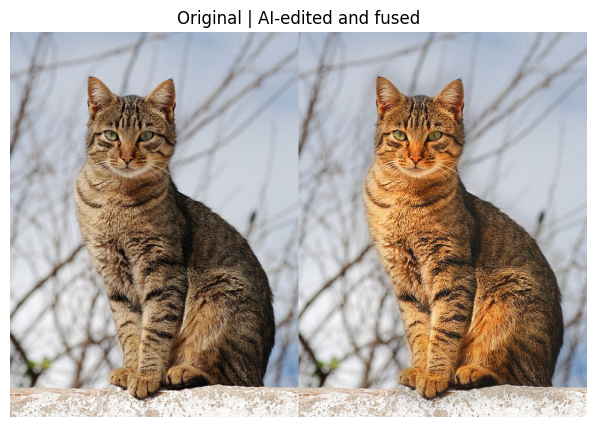

**Say:** The system uses Mask R-CNN to identify the subject. It analyses the subject and background separately, applies different editing parameters, sharpens the image and uses multiscale pyramid fusion to combine the results.

---
## 2. Performance Across Different Image Resolutions

Megapixels,Width,Height,Raw CPU (ms),Raw GPU (ms),Edited CPU (ms),Edited GPU (ms)
0.250000,432,577,2.560000,2.400000,45.040000,10.680000
1.000000,865,1155,11.760000,6.820000,214.760000,33.100000
4.000000,1730,2311,66.610000,32.990000,1279.770000,239.330000
8.000000,2447,3269,141.200000,59.830000,2581.400000,333.330000


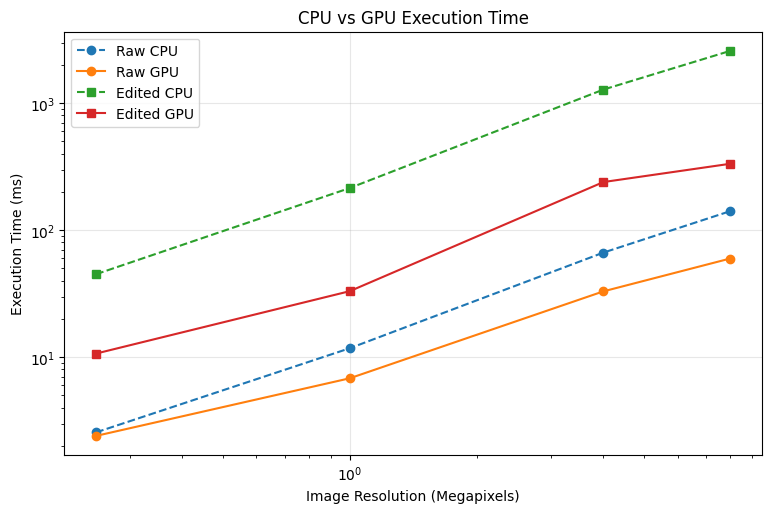

**Say:** We tested four image resolutions. The purpose is to understand how processing time changes as the number of pixels increases. The crossover point indicates where GPU processing becomes faster than CPU processing.

---
## 3. GPU Speedup

Megapixels,Raw Speedup (x),Edited Speedup (x)
0.250000,1.066000,4.216000
1.000000,1.724000,6.488000
4.000000,2.019000,5.347000
8.000000,2.360000,7.744000


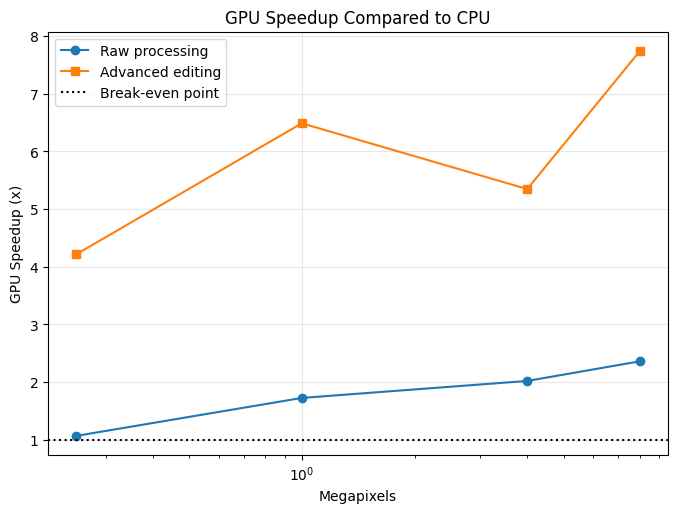

**Say:** Speedup is calculated by dividing CPU execution time by GPU execution time. A value above one means the GPU is faster, while a value below one means the CPU is faster.

---
## 4. Where Does GPU Processing Time Go?

Megapixels,GPU End-to-end (ms),GPU Kernels Only (ms),Other Operations (ms),Other Operations (%)
0.250000,10.680000,2.710000,7.970000,74.650000
1.000000,33.100000,6.480000,26.620000,80.440000
4.000000,239.330000,34.370000,204.960000,85.640000
8.000000,333.330000,29.810000,303.520000,91.060000


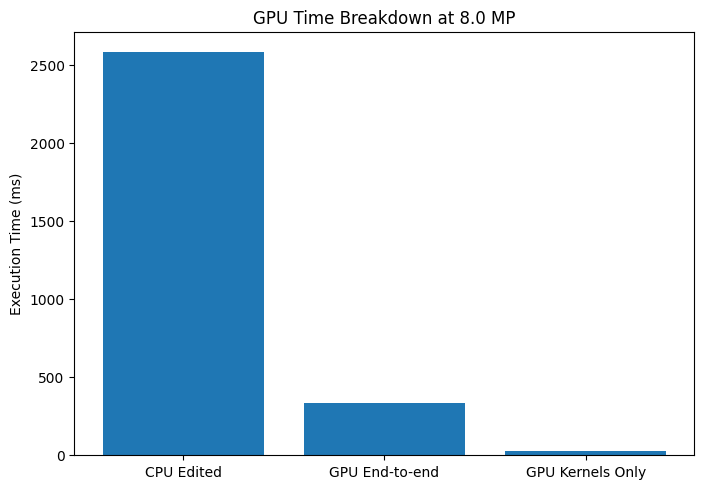

**Say:** The GPU kernel-only time measures the two custom CUDA image-processing kernels while the image is already on the GPU. End-to-end time also includes data transfers and the PyTorch pyramid fusion stage. These are different measurements and should not be confused.

---
## 5. Correctness: CPU vs GPU Output

Megapixels,PSNR (dB),SSIM,Raw Maximum Absolute Error
0.250000,141.943020,1.000000,0.000000
1.000000,142.217070,1.000000,0.000000
4.000000,140.629700,1.000000,0.000000
8.000000,140.148460,nan,0.000000


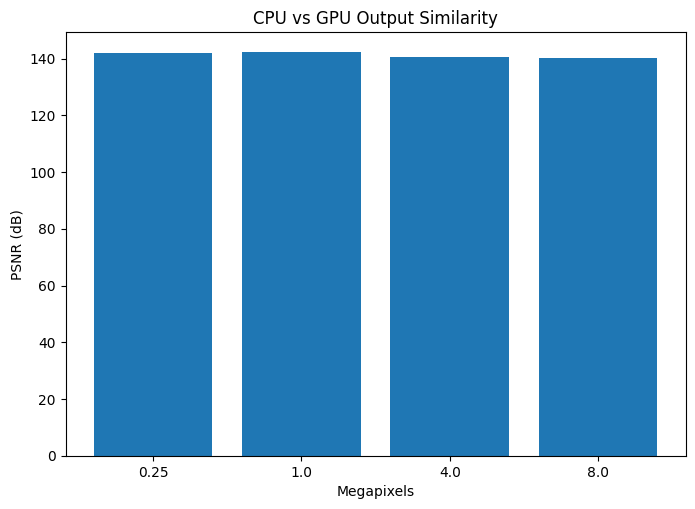

**Say:** PSNR measures pixel-level similarity between the CPU and GPU edited outputs. SSIM measures structural similarity. Higher values indicate greater similarity. SSIM was skipped at 8 MP to reduce computation.

---
## 6. AI Subject Detection: Mask R-CNN

Device,Inference_time_ms,Speedup
CPU,6800.494000,1.000000
GPU,126.548000,53.738000


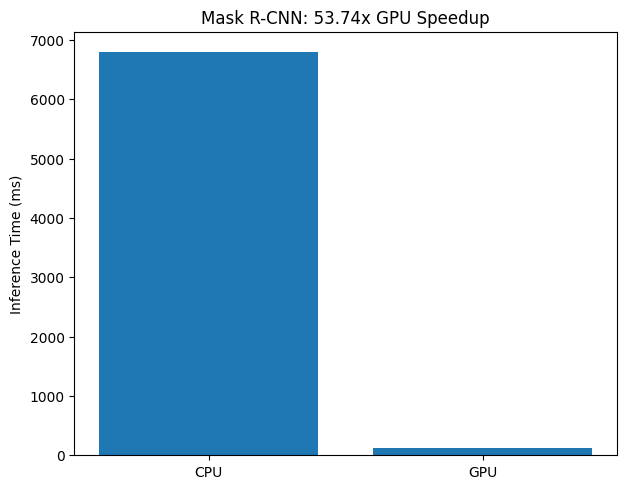

**Say:** Mask R-CNN is a deep learning model used for object detection and instance segmentation. We measure its inference time separately on CPU and GPU. This shows how acceleration affects the AI detection stage.

---
## 7. Experimental Summary

,Workload,GPU faster at all tested sizes,GPU wins at tested sizes,Number of tested sizes
0,Basic colour grading,True,4,4
1,Advanced AI-assisted editing,True,4,4


**Say:** Our experiment compares two different workloads: basic colour grading and a more computationally demanding AI-assisted editing pipeline. The results help establish how image resolution and computational workload influence CPU and GPU performance.

---
## 8. Generated Research Files

Available: results.csv
Available: detection_results.csv
Available: dashboard.png
Available: before_after.png

Presentation preparation completed.


In [14]:
#extra
# ============================================================
# PRESENTATION CELL
# Tables, charts and explanations in presentation order
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ------------------------------------------------------------
# 0. RECOVER EXPERIMENT RESULTS
# ------------------------------------------------------------

if "df" not in globals():
    df = pd.read_csv("results.csv")

detection_df = pd.read_csv("detection_results.csv")

cpu_detect_ms = float(
    detection_df.loc[
        detection_df["Device"] == "CPU",
        "Inference_time_ms"
    ].iloc[0]
)

gpu_detect_ms = float(
    detection_df.loc[
        detection_df["Device"] == "GPU",
        "Inference_time_ms"
    ].iloc[0]
)

if "hero" not in globals():
    hero = {}

if not hero and os.path.exists("before_after.png"):
    print("Using saved before-and-after image.")


def title(text):
    display(Markdown(f"---\n## {text}"))


def say(text):
    display(Markdown(f"**Say:** {text}"))


mp = df["megapixels"]


# ============================================================
# 1. WHAT WE BUILT
# ============================================================

title("1. What We Built: Before and After")

if hero:

    plt.figure(figsize=(10, 5))

    plt.imshow(
        np.clip(
            np.concatenate(
                [hero["orig"], hero["out"]],
                axis=1
            ),
            0, 1
        )
    )

    plt.axis("off")

    plt.title(
        "Original | AI-edited and fused"
    )

    plt.show()

elif os.path.exists("before_after.png"):

    from PIL import Image

    display(Image.open("before_after.png"))

else:

    print("Run the experiment cell to generate the image.")

say(
    "The system uses Mask R-CNN to identify the subject. "
    "It analyses the subject and background separately, "
    "applies different editing parameters, sharpens the image "
    "and uses multiscale pyramid fusion to combine the results."
)


# ============================================================
# 2. IMAGE RESOLUTION AND EXECUTION TIME
# ============================================================

title("2. Performance Across Different Image Resolutions")

t2 = df[
    [
        "megapixels",
        "width",
        "height",
        "raw_cpu_ms",
        "raw_gpu_ms",
        "edited_cpu_ms",
        "edited_gpu_ms"
    ]
].round(2)

t2.columns = [
    "Megapixels",
    "Width",
    "Height",
    "Raw CPU (ms)",
    "Raw GPU (ms)",
    "Edited CPU (ms)",
    "Edited GPU (ms)"
]

display(t2.style.hide(axis="index"))


plt.figure(figsize=(9, 5.5))

plt.plot(
    mp, df.raw_cpu_ms,
    "o--", label="Raw CPU"
)

plt.plot(
    mp, df.raw_gpu_ms,
    "o-", label="Raw GPU"
)

plt.plot(
    mp, df.edited_cpu_ms,
    "s--", label="Edited CPU"
)

plt.plot(
    mp, df.edited_gpu_ms,
    "s-", label="Edited GPU"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Image Resolution (Megapixels)")
plt.ylabel("Execution Time (ms)")

plt.title("CPU vs GPU Execution Time")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


say(
    "We tested four image resolutions. "
    "The purpose is to understand how processing time changes "
    "as the number of pixels increases. "
    "The crossover point indicates where GPU processing "
    "becomes faster than CPU processing."
)


# ============================================================
# 3. GPU SPEEDUP
# ============================================================

title("3. GPU Speedup")

t3 = df[
    [
        "megapixels",
        "raw_speedup",
        "edited_speedup"
    ]
].round(3)

t3.columns = [
    "Megapixels",
    "Raw Speedup (x)",
    "Edited Speedup (x)"
]

display(t3.style.hide(axis="index"))


plt.figure(figsize=(8, 5.5))

plt.plot(
    mp,
    df.raw_speedup,
    "o-",
    label="Raw processing"
)

plt.plot(
    mp,
    df.edited_speedup,
    "s-",
    label="Advanced editing"
)

plt.axhline(
    1,
    color="black",
    linestyle=":",
    label="Break-even point"
)

plt.xscale("log")

plt.xlabel("Megapixels")
plt.ylabel("GPU Speedup (x)")

plt.title("GPU Speedup Compared to CPU")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


say(
    "Speedup is calculated by dividing CPU execution time "
    "by GPU execution time. A value above one means the GPU "
    "is faster, while a value below one means the CPU is faster."
)


# ============================================================
# 4. GPU TIME BREAKDOWN
# ============================================================

title("4. Where Does GPU Processing Time Go?")

t4 = df[
    [
        "megapixels",
        "edited_gpu_ms",
        "edited_gpu_kernels_only_ms"
    ]
].copy()

t4["other_ms"] = (
    t4["edited_gpu_ms"]
    - t4["edited_gpu_kernels_only_ms"]
)

t4["other_pct"] = (
    100 * t4["other_ms"]
    / t4["edited_gpu_ms"]
)

t4 = t4.round(2)

t4.columns = [
    "Megapixels",
    "GPU End-to-end (ms)",
    "GPU Kernels Only (ms)",
    "Other Operations (ms)",
    "Other Operations (%)"
]

display(t4.style.hide(axis="index"))


last = df.iloc[-1]

plt.figure(figsize=(8, 5.5))

plt.bar(
    [
        "CPU Edited",
        "GPU End-to-end",
        "GPU Kernels Only"
    ],
    [
        last.edited_cpu_ms,
        last.edited_gpu_ms,
        last.edited_gpu_kernels_only_ms
    ]
)

plt.ylabel("Execution Time (ms)")

plt.title(
    f"GPU Time Breakdown at {last.megapixels} MP"
)

plt.show()


say(
    "The GPU kernel-only time measures the two custom CUDA "
    "image-processing kernels while the image is already on "
    "the GPU. End-to-end time also includes data transfers "
    "and the PyTorch pyramid fusion stage. These are different "
    "measurements and should not be confused."
)


# ============================================================
# 5. OUTPUT QUALITY
# ============================================================

title("5. Correctness: CPU vs GPU Output")

t5 = df[
    [
        "megapixels",
        "psnr_db",
        "ssim",
        "raw_max_abs_err"
    ]
].round(5)

t5.columns = [
    "Megapixels",
    "PSNR (dB)",
    "SSIM",
    "Raw Maximum Absolute Error"
]

display(t5.style.hide(axis="index"))


plt.figure(figsize=(8, 5.5))

plt.bar(
    [str(m) for m in mp],
    df.psnr_db
)

plt.xlabel("Megapixels")
plt.ylabel("PSNR (dB)")

plt.title("CPU vs GPU Output Similarity")

plt.show()


say(
    "PSNR measures pixel-level similarity between the CPU "
    "and GPU edited outputs. SSIM measures structural "
    "similarity. Higher values indicate greater similarity. "
    "SSIM was skipped at 8 MP to reduce computation."
)


# ============================================================
# 6. AI MODEL PERFORMANCE
# ============================================================

title("6. AI Subject Detection: Mask R-CNN")

display(
    detection_df.round(3).style.hide(axis="index")
)


plt.figure(figsize=(7, 5.5))

plt.bar(
    ["CPU", "GPU"],
    [cpu_detect_ms, gpu_detect_ms]
)

plt.ylabel("Inference Time (ms)")

plt.title(
    f"Mask R-CNN: "
    f"{cpu_detect_ms / gpu_detect_ms:.2f}x GPU Speedup"
)

plt.show()


say(
    "Mask R-CNN is a deep learning model used for object "
    "detection and instance segmentation. We measure its "
    "inference time separately on CPU and GPU. This shows "
    "how acceleration affects the AI detection stage."
)


# ============================================================
# 7. FINAL SUMMARY
# ============================================================

title("7. Experimental Summary")

raw_wins = df[df.raw_speedup > 1]

edited_wins = df[df.edited_speedup > 1]

summary = pd.DataFrame({
    "Workload": [
        "Basic colour grading",
        "Advanced AI-assisted editing"
    ],

    "GPU faster at all tested sizes": [
        len(raw_wins) == len(df),
        len(edited_wins) == len(df)
    ],

    "GPU wins at tested sizes": [
        len(raw_wins),
        len(edited_wins)
    ],

    "Number of tested sizes": [
        len(df),
        len(df)
    ]
})

display(summary)


say(
    "Our experiment compares two different workloads: "
    "basic colour grading and a more computationally demanding "
    "AI-assisted editing pipeline. The results help establish "
    "how image resolution and computational workload influence "
    "CPU and GPU performance."
)


# ============================================================
# 8. GENERATED FILES
# ============================================================

title("8. Generated Research Files")

files = [
    "results.csv",
    "detection_results.csv",
    "dashboard.png",
    "before_after.png"
]

for f in files:

    if os.path.exists(f):
        print("Available:", f)
    else:
        print("Not generated:", f)

print("\nPresentation preparation completed.")


Exposure (suggested -1.5 to 1.5, brightness in stops): 1
Contrast (suggested -0.5 to 0.5): 0.2
Highlights (suggested -0.5 to 0.5): 1.2
Shadows (suggested -0.5 to 0.5): -0.2
Saturation (suggested -0.5 to 0.5): 0.3
Temperature (suggested -0.3 to 0.3, positive = warmer): -0.2
Using: [ 1.   0.2  1.2 -0.2  0.3 -0.2]
CPU 45.7 ms | GPU 14.7 ms | speedup 3.11x


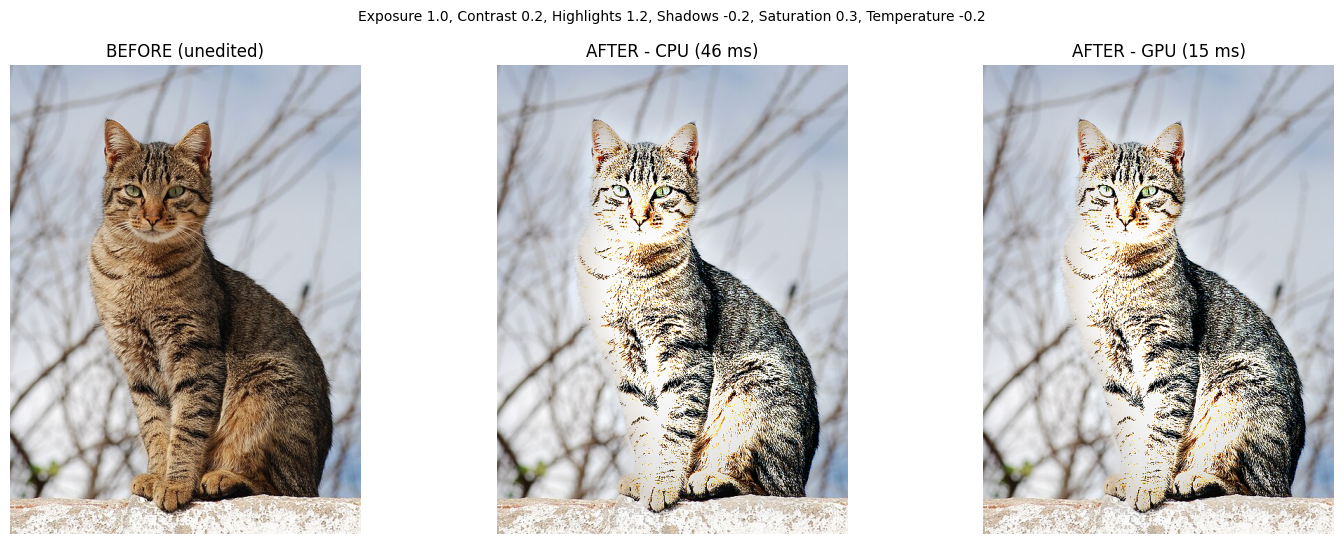

In [18]:
# ===== USER EDIT: prompts -> edit -> BEFORE / AFTER pictures =====
# (run your all-in-one cell first, in the same session, with the GPU on)

def ask(name, hint):
    while True:
        try:
            return float(input(f"{name} (suggested {hint}): "))
        except ValueError:
            print("Please type a number, for example 0.3 or -0.2.")

exposure    = ask("Exposure",    "-1.5 to 1.5, brightness in stops")
contrast    = ask("Contrast",    "-0.5 to 0.5")
highlights  = ask("Highlights",  "-0.5 to 0.5")
shadows     = ask("Shadows",     "-0.5 to 0.5")
saturation  = ask("Saturation",  "-0.5 to 0.5")
temperature = ask("Temperature", "-0.3 to 0.3, positive = warmer")

user_params = np.array([exposure, contrast, highlights, shadows, saturation, temperature], dtype=np.float32)
print("Using:", user_params)

img  = np.ascontiguousarray(img_array, dtype=np.float32)    # the unedited original
mask = np.ascontiguousarray(mask_np,  dtype=np.float32)
up_d = cuda.to_device(user_params)

def user_gpu():
    d_img, d_mask = cuda.to_device(img), cuda.to_device(mask)
    d_edit, d_sharp = cuda.device_array_like(d_img), cuda.device_array_like(d_img)
    g = grid_for(*img.shape[:2])
    lightroom_kernel[g, TPB](d_img, d_mask, up_d, up_d, np.float32(0.35), d_edit)
    sharpen_kernel[g, TPB](d_edit, d_mask, np.float32(0.8), np.float32(0.2), d_sharp)
    return pyramid_blend_gpu(d_sharp.copy_to_host(), img, mask, 5, device)

def user_cpu():
    e = edit_cpu(img, user_params)
    h, w = img.shape[:2]
    yy = (np.arange(h, dtype=np.float32) - h/2) / (h/2)
    xx = (np.arange(w, dtype=np.float32) - w/2) / (w/2)
    v = 1.0 - 0.35 * (yy[:, None]**2 + xx[None, :]**2) * 0.5
    e = (e * v[..., None]).astype(np.float32)
    return pyramid_blend(sharpen_cpu(e, mask, 0.8, 0.2), img, mask, 5)

gpu_ms, after_gpu = bench(user_gpu, 3)
cpu_ms, after_cpu = bench(user_cpu, 2, warmup=False)
print(f"CPU {cpu_ms:.1f} ms | GPU {gpu_ms:.1f} ms | speedup {cpu_ms/gpu_ms:.2f}x")

plt.figure(figsize=(15, 5.5))
plt.subplot(1, 3, 1); plt.imshow(np.clip(img, 0, 1));         plt.title("BEFORE (unedited)"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(np.clip(after_cpu, 0, 1));   plt.title(f"AFTER - CPU ({cpu_ms:.0f} ms)"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(np.clip(after_gpu, 0, 1));   plt.title(f"AFTER - GPU ({gpu_ms:.0f} ms)"); plt.axis("off")
plt.suptitle(f"Exposure {exposure}, Contrast {contrast}, Highlights {highlights}, "
             f"Shadows {shadows}, Saturation {saturation}, Temperature {temperature}", fontsize=10)
plt.tight_layout(); plt.savefig("user_edit_before_after.png", dpi=150); plt.show()

In [19]:
#to calculate the predicted runtimes
import numpy as np, time, torch
from numba import cuda

def med(fn, reps=5, warm=1, sync=False):
    for _ in range(warm): fn()
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn()
        if sync: cuda.synchronize(); torch.cuda.synchronize()
        ts.append(time.perf_counter() - t)
    return float(np.median(ts))

n = 64_000_000                                   # 256 MB float32 arrays
a = np.random.rand(n).astype(np.float32); b = np.random.rand(n).astype(np.float32)

# 1. CPU streaming bandwidth (a+b: read 8 B, write 4 B per element, with allocation like NumPy edits)
cpu_bw = 12 * n / med(lambda: a + b)

# 2. Host<->device bandwidth (pageable memory)
h2d_bw = 4 * n / med(lambda: cuda.to_device(a))
d = cuda.to_device(a)
d2h_bw = 4 * n / med(lambda: d.copy_to_host())

# 3. GPU device-memory bandwidth (copy kernel: read 4 B, write 4 B)
@cuda.jit
def copy_k(x, y):
    i = cuda.grid(1)
    if i < x.size: y[i] = x[i]
dx = cuda.to_device(a); dy = cuda.device_array_like(dx); g = (n + 255) // 256
copy_k[g, 256](dx, dy); cuda.synchronize()
gpu_bw = 8 * n / med(lambda: copy_k[g, 256](dx, dy), sync=True)

# 4. Fixed overheads
tiny = cuda.to_device(np.zeros(1, np.float32))
launch = med(lambda: copy_k[1, 32](tiny, tiny), reps=50, sync=True)
alloc = med(lambda: cuda.device_array(1_000_000, np.float32), reps=20, sync=True)
x = torch.zeros(1, device="cuda"); torch.add(x, 1)
torch_op = med(lambda: torch.add(x, 1), reps=200, sync=True)

# 5. Compute throughput (FP32 matmul)
A = torch.rand(1024, 1024); cpu_flops = 2 * 1024**3 / med(lambda: torch.mm(A, A))
Ag = torch.rand(4096, 4096, device="cuda")
gpu_flops = 2 * 4096**3 / med(lambda: torch.mm(Ag, Ag), sync=True)

print(f"CPU bandwidth   {cpu_bw/1e9:7.1f} GB/s")
print(f"H2D / D2H       {h2d_bw/1e9:7.1f} / {d2h_bw/1e9:.1f} GB/s")
print(f"GPU bandwidth   {gpu_bw/1e9:7.1f} GB/s")
print(f"launch {launch*1e6:.0f} us | alloc {alloc*1e6:.0f} us | torch op {torch_op*1e6:.0f} us")
print(f"CPU matmul {cpu_flops/1e9:.0f} GFLOPS | GPU matmul {gpu_flops/1e12:.2f} TFLOPS")

# ---- Predictions from MEASURED parameters (same byte counts as before) ----
MP = [0.25, 1, 4, 8]
act = dict(raw_cpu=[2.0, 8.8, 47.2, 93.2], raw_gpu=[2.3, 6.5, 32.7, 59.1],
           ed_cpu=[43.7, 204.9, 1248.3, 2570.3], ed_gpu=[10.4, 33.0, 196.4, 322.0])
ovh_edit = 2 * launch + 120 * torch_op + 10 * alloc      # ~120 torch ops in fusion (estimate)
print(f"\n{'MP':>5} | {'rawCPU p/a':>14} | {'rawGPU p/a':>14} | {'edCPU p/a':>16} | {'edGPU p/a':>16}")
for i, m in enumerate(MP):
    N = m * 1e6
    p_rc = N * 48 / cpu_bw * 1e3
    p_rg = (N * 12 / h2d_bw + N * 12 / d2h_bw + N * 24 / gpu_bw + launch + 2 * alloc) * 1e3
    p_ec = N * 1850 / cpu_bw * 1e3
    p_eg = (N * 44 / h2d_bw + N * 24 / d2h_bw + N * 456 / gpu_bw + ovh_edit) * 1e3
    print(f"{m:>5} | {p_rc:6.1f}/{act['raw_cpu'][i]:<7} | {p_rg:6.1f}/{act['raw_gpu'][i]:<7} | "
          f"{p_ec:7.1f}/{act['ed_cpu'][i]:<8} | {p_eg:7.1f}/{act['ed_gpu'][i]:<8}")
print(f"Mask R-CNN predicted: CPU {134.38e9/cpu_flops*1e3:.0f} ms (actual 4982), "
      f"GPU {134.38e9/gpu_flops*1e3:.0f} ms (actual 159)")

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:690: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


CPU bandwidth       6.4 GB/s
H2D / D2H           3.9 / 2.6 GB/s
GPU bandwidth     222.7 GB/s
launch 67 us | alloc 321 us | torch op 56 us
CPU matmul 113 GFLOPS | GPU matmul 3.45 TFLOPS

   MP |     rawCPU p/a |     rawGPU p/a |        edCPU p/a |        edGPU p/a
 0.25 |    1.9/2.0     |    2.6/2.3     |    71.9/43.7     |    15.7/10.4    
    1 |    7.5/8.8     |    8.4/6.5     |   287.6/204.9    |    32.4/33.0    
    4 |   29.8/47.2    |   31.5/32.7    |  1150.3/1248.3   |    99.2/196.4   
    8 |   59.7/93.2    |   62.3/59.1    |  2300.7/2570.3   |   188.4/322.0   
Mask R-CNN predicted: CPU 1188 ms (actual 4982), GPU 39 ms (actual 159)
